In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

sns.set_theme(style="whitegrid")

df_sleep = pd.read_csv('../data/processed/sleep_stage.csv')

display(df_sleep.head())

,create_sh_ver,start_time,sleep_id,modify_sh_ver,update_time,create_time,stage,time_offset,deviceuuid,pkg_name,end_time,datauuid
0,63051050,2025-11-05 3:29:47,00353839-3137-3736-3439-333332363731,63051050,2025-11-05 10:44:39,2025-11-05 10:44:39,40002,UTC-0300,g1bnYRM2yN,com.sec.android.app.shealth,2025-11-05 3:53:47,1adfa0ac-61f2-4cb3-aeff-6a4b237ca2c6
1,63051050,2025-11-05 3:53:47,00353839-3137-3736-3439-333332363731,63051050,2025-11-05 10:44:39,2025-11-05 10:44:39,40001,UTC-0300,g1bnYRM2yN,com.sec.android.app.shealth,2025-11-05 4:29:47,6d85e430-3335-42df-bc53-069f1090e316
2,63051050,2025-11-05 4:29:47,00353839-3137-3736-3439-333332363731,63051050,2025-11-05 10:44:39,2025-11-05 10:44:39,40002,UTC-0300,g1bnYRM2yN,com.sec.android.app.shealth,2025-11-05 4:50:47,a0df1df0-7cb7-4cf8-852b-56a97270772a
3,63051050,2025-11-05 4:50:47,00353839-3137-3736-3439-333332363731,63051050,2025-11-05 10:44:39,2025-11-05 10:44:39,40001,UTC-0300,g1bnYRM2yN,com.sec.android.app.shealth,2025-11-05 4:51:47,62e00721-d050-4e25-ab53-b398546af6a8
4,63051050,2025-11-05 4:51:47,00353839-3137-3736-3439-333332363731,63051050,2025-11-05 10:44:39,2025-11-05 10:44:39,40002,UTC-0300,g1bnYRM2yN,com.sec.android.app.shealth,2025-11-05 4:55:47,0ca14bc1-ffa9-44a2-9590-54d5f2f746f0


In [2]:
df_sleep['start_time'] = pd.to_datetime(df_sleep['start_time']) - pd.Timedelta(hours=3)
df_sleep['end_time'] = pd.to_datetime(df_sleep['end_time']) - pd.Timedelta(hours=3)
df_sleep['create_time'] = pd.to_datetime(df_sleep['create_time']) - pd.Timedelta(hours=3)
df_sleep['update_time'] = pd.to_datetime(df_sleep['update_time']) - pd.Timedelta(hours=3)

df_sleep['duration_mins'] = (df_sleep['end_time'] - df_sleep['start_time']).dt.total_seconds() / 60
df_sleep['sleep_date'] = (df_sleep['start_time'] - pd.Timedelta(hours=12)).dt.date

stage_mapping = {
    40001: 'Acordado',
    40002: 'Leve (Light)',
    40003: 'Profundo (Deep)',
    40004: 'REM'
}
df_sleep['stage_name'] = df_sleep['stage'].map(stage_mapping)

df_sleep['sleep_date'] = (df_sleep['start_time'] - pd.Timedelta(hours=12)).dt.date

colunas_uteis = ['sleep_date', 'sleep_id', 'start_time', 'end_time', 'duration_mins', 'stage', 'stage_name']
df_analysis = df_sleep[colunas_uteis].copy()

df_analysis = df_analysis.dropna(subset=['stage_name', 'duration_mins'])

display(df_analysis.head())

,sleep_date,sleep_id,start_time,end_time,duration_mins,stage,stage_name
0,2025-11-04,00353839-3137-3736-3439-333332363731,2025-11-05 00:29:47,2025-11-05 00:53:47,24.0,40002,Leve (Light)
1,2025-11-04,00353839-3137-3736-3439-333332363731,2025-11-05 00:53:47,2025-11-05 01:29:47,36.0,40001,Acordado
2,2025-11-04,00353839-3137-3736-3439-333332363731,2025-11-05 01:29:47,2025-11-05 01:50:47,21.0,40002,Leve (Light)
3,2025-11-04,00353839-3137-3736-3439-333332363731,2025-11-05 01:50:47,2025-11-05 01:51:47,1.0,40001,Acordado
4,2025-11-04,00353839-3137-3736-3439-333332363731,2025-11-05 01:51:47,2025-11-05 01:55:47,4.0,40002,Leve (Light)


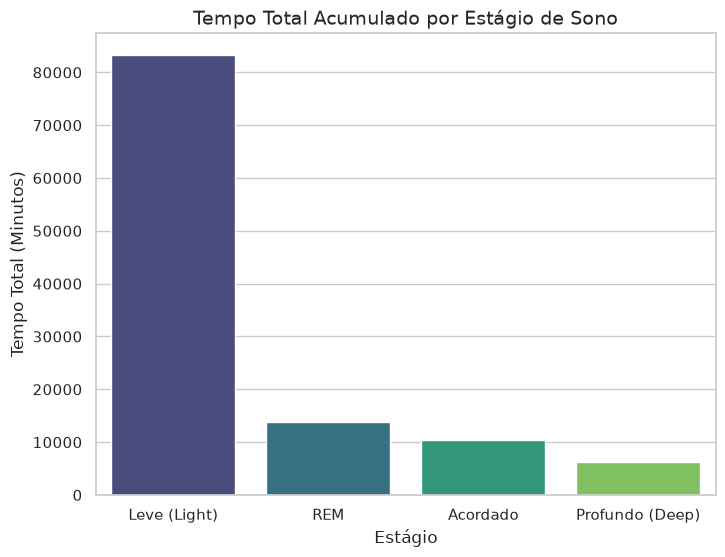

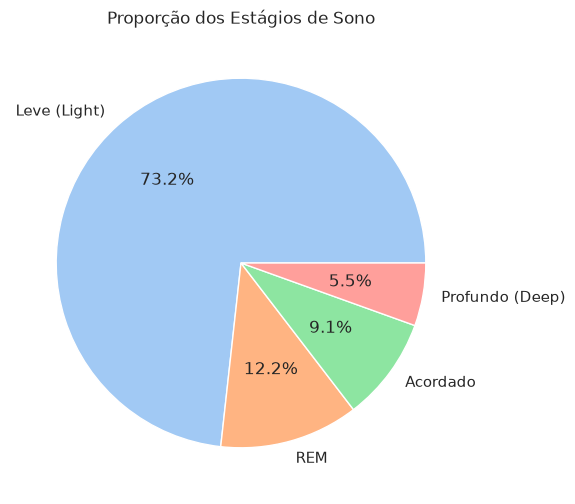

In [3]:
plt.figure(figsize=(8, 6))
stage_totals = df_analysis.groupby('stage_name')['duration_mins'].sum().sort_values(ascending=False)

sns.barplot(
    x=stage_totals.index, 
    y=stage_totals.values, 
    hue=stage_totals.index, 
    palette='viridis', 
    legend=False
)
plt.title('Tempo Total Acumulado por Estágio de Sono', fontsize=14)
plt.ylabel('Tempo Total (Minutos)', fontsize=12)
plt.xlabel('Estágio', fontsize=12)
plt.show()

plt.figure(figsize=(6, 6))
plt.pie(stage_totals.values, labels=stage_totals.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title('Proporção dos Estágios de Sono')
plt.show()

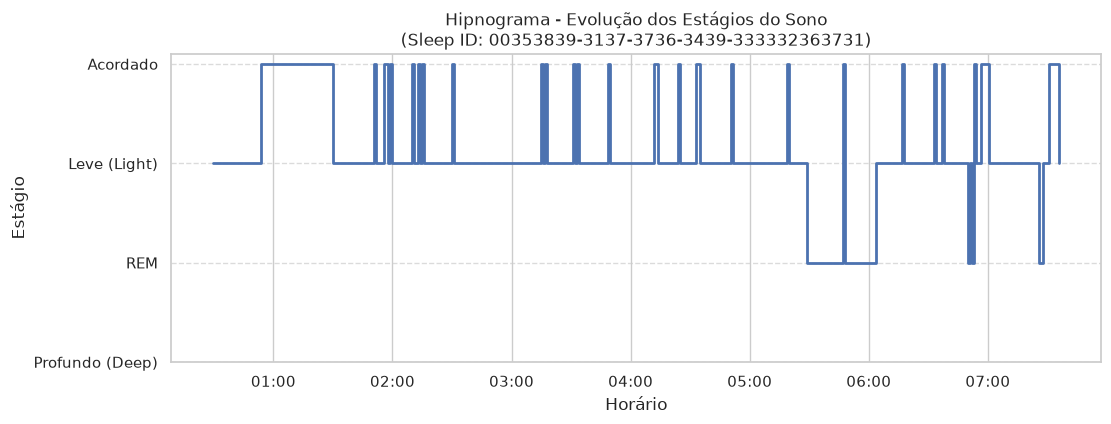

In [4]:
exemplo_sleep_id = df_analysis['sleep_id'].iloc[0]
df_night = df_analysis[df_analysis['sleep_id'] == exemplo_sleep_id].sort_values('start_time')

ordem_estagios = {'Profundo (Deep)': 1, 'REM': 2, 'Leve (Light)': 3, 'Acordado': 4}
df_night['stage_level'] = df_night['stage_name'].map(ordem_estagios)

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(df_night['start_time'], df_night['stage_level'], where='post', color='b', linewidth=2)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set_yticks(list(ordem_estagios.values()))
ax.set_yticklabels(list(ordem_estagios.keys()))

plt.title(f'Hipnograma - Evolução dos Estágios do Sono\n(Sleep ID: {exemplo_sleep_id})')
plt.xlabel('Horário')
plt.ylabel('Estágio')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()

stage_name,Acordado,Leve (Light),Profundo (Deep),REM,Tempo Total
sleep_id,,,,,
00353839-3137-3030-3030-363535373731,37.0,329.0,23.0,39.0,428.0
00353839-3137-3030-3035-363633373731,54.0,367.0,21.0,69.0,511.0
00353839-3137-3030-3132-333236363731,56.0,365.0,14.0,27.0,462.0
00353839-3137-3030-3139-353931383731,36.0,353.0,34.0,97.0,520.0
00353839-3137-3030-3837-353337363731,43.0,380.0,8.0,84.0,515.0


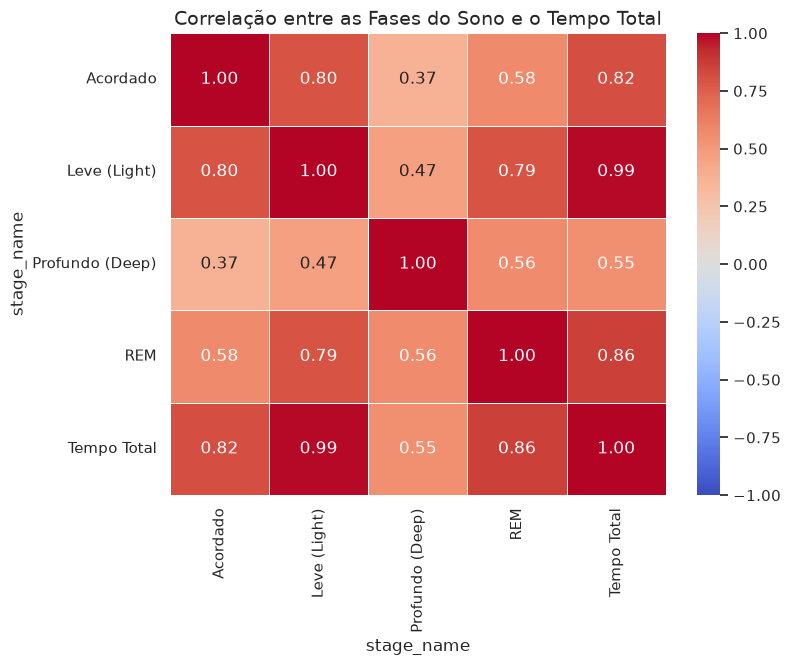

In [5]:
df_pivot = df_analysis.pivot_table(
    index='sleep_id', 
    columns='stage_name', 
    values='duration_mins', 
    aggfunc='sum'
).fillna(0)

df_pivot['Tempo Total'] = df_pivot.sum(axis=1)

display(df_pivot.head())

plt.figure(figsize=(8, 6))
corr_matrix = df_pivot.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Correlação entre as Fases do Sono e o Tempo Total', fontsize=14)
plt.show()

In [6]:
print("Média de tempo gasto em cada estágio por noite:")
medias = df_pivot.mean().round(2)
for estagio, valor in medias.items():
    print(f"- {estagio}: {valor} min ({valor/60:.2f} horas)")

Média de tempo gasto em cada estágio por noite:
- Acordado: 30.49 min (0.51 horas)
- Leve (Light): 245.71 min (4.10 horas)
- Profundo (Deep): 18.44 min (0.31 horas)
- REM: 40.81 min (0.68 horas)
- Tempo Total: 335.45 min (5.59 horas)
